# Estimación del costo médico anual por afiliado

**Proyecto:** Costos médicos y bienestar del paciente · Aseguradora de salud privada
**Asignatura:** SCY1102 Gestión de Proyectos de Datos · Duoc UC
**Evaluación:** EP5 — Implementación técnica

---

Este cuaderno es la evidencia técnica del proyecto. Reproduce de punta a punta el pipeline
comprometido en el plan: carga, diagnóstico de calidad, preparación, línea base, comparación de
modelos, verificación de los criterios de aceptación y serialización del modelo final.

**Trazabilidad con el plan.** Cada sección indica el requerimiento u objetivo que verifica:

| Código | Qué exige |
|---|---|
| RF-01 | Estimar el costo anual con un intervalo de confianza del 90 % |
| RF-02 | Entregar el aporte de cada variable, global y por afiliado |
| RF-03 | Simular escenarios sobre factores modificables |
| RNF-01 | Trabajar sin identificadores directos ni atributos protegidos |
| RNF-02 | No introducir sesgos sistemáticos entre subgrupos |
| RD-01 a RD-04 | Requerimientos sobre los datos de entrada |
| OE-1 a OE-5 | Objetivos específicos del proyecto |

**Reproducibilidad.** Semilla fija en todo el cuaderno. Ejecutar las celdas en orden.

## 1. Entorno y carga de datos

In [1]:
import sys, json, platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline

SEMILLA = 42
np.random.seed(SEMILLA)

print("Python     ", sys.version.split()[0], "|", platform.system())
print("pandas     ", pd.__version__)
print("numpy      ", np.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib ", matplotlib.__version__)

Python      3.13.18 | Linux
pandas      3.0.5
numpy       2.5.3
scikit-learn 1.9.1
matplotlib  3.11.2


In [2]:
d = pd.read_csv("insurance.csv")
print("Dimensiones:", d.shape)
d.head()

Dimensiones: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Diagnóstico de calidad de datos

Verifica los requerimientos de datos **RD-01** (profundidad histórica), **RD-02** (cobertura de los
campos autodeclarados) y **RD-03** (clave de unión).

In [3]:
print("=== TIPOS Y COBERTURA ===")
cob = pd.DataFrame({
    "tipo": d.dtypes.astype(str),
    "nulos": d.isna().sum(),
    "pct_nulos": (d.isna().mean() * 100).round(2),
    "valores_unicos": d.nunique(),
})
print(cob.to_string())
print()
print("Total de valores faltantes en el conjunto:", int(d.isna().sum().sum()))
print("Registros duplicados:", int(d.duplicated().sum()))

=== TIPOS Y COBERTURA ===
             tipo  nulos  pct_nulos  valores_unicos
age         int64      0        0.0              47
sex           str      0        0.0               2
bmi       float64      0        0.0             548
children    int64      0        0.0               6
smoker        str      0        0.0               2
region        str      0        0.0               4
charges   float64      0        0.0            1337

Total de valores faltantes en el conjunto: 0
Registros duplicados: 1


In [4]:
print("=== VERIFICACIÓN DE REQUERIMIENTOS DE DATOS ===")
print()
print("RD-01 · Mínimo tres períodos anuales cerrados")
cols_tiempo = [c for c in d.columns if any(k in c.lower() for k in ("year", "anio", "año", "fecha", "date", "periodo"))]
print("   Columnas con dimensión temporal:", cols_tiempo if cols_tiempo else "ninguna")
print("   RESULTADO: NO CUMPLE — el conjunto es un corte transversal único.")
print("   Consecuencia: la línea base se construye particionando el mismo período,")
print("   no comparando años consecutivos. Queda declarado como limitación.")
print()
print("RD-02 · Cobertura utilizable de IMC y tabaquismo")
print(f"   Nulos en bmi: {d.bmi.isna().sum()} | Nulos en smoker: {d.smoker.isna().sum()}")
print("   RESULTADO: CUMPLE — cobertura completa, no se requiere imputación.")
print("   El riesgo R-03 del registro de riesgos no se materializó.")
print()
print("RD-03 · Clave de unión única entre fuentes")
print("   El conjunto llega ya consolidado; no hay identificador de afiliado expuesto.")
print("   RESULTADO: CUMPLE por construcción, y es consistente con RNF-01.")

=== VERIFICACIÓN DE REQUERIMIENTOS DE DATOS ===

RD-01 · Mínimo tres períodos anuales cerrados
   Columnas con dimensión temporal: ninguna
   RESULTADO: NO CUMPLE — el conjunto es un corte transversal único.
   Consecuencia: la línea base se construye particionando el mismo período,
   no comparando años consecutivos. Queda declarado como limitación.

RD-02 · Cobertura utilizable de IMC y tabaquismo
   Nulos en bmi: 0 | Nulos en smoker: 0
   RESULTADO: CUMPLE — cobertura completa, no se requiere imputación.
   El riesgo R-03 del registro de riesgos no se materializó.

RD-03 · Clave de unión única entre fuentes
   El conjunto llega ya consolidado; no hay identificador de afiliado expuesto.
   RESULTADO: CUMPLE por construcción, y es consistente con RNF-01.


In [5]:
print("=== DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ===")
print(d.charges.describe().round(0).to_string())
print()
print("Asimetría (skew):", round(float(d.charges.skew()), 2))
print("La media supera a la mediana en", round(float(d.charges.mean() - d.charges.median()), 0),
      "— cola derecha pronunciada.")
print()
print("=== VARIABLES CATEGÓRICAS ===")
for c in ["sex", "smoker", "region"]:
    print(f"{c:8}", d[c].value_counts().to_dict())

=== DISTRIBUCIÓN DE LA VARIABLE OBJETIVO ===
count     1338.0
mean     13270.0
std      12110.0
min       1122.0
25%       4740.0
50%       9382.0
75%      16640.0
max      63770.0

Asimetría (skew): 1.52
La media supera a la mediana en 3888.0 — cola derecha pronunciada.

=== VARIABLES CATEGÓRICAS ===
sex      {'male': 676, 'female': 662}
smoker   {'no': 1064, 'yes': 274}
region   {'southeast': 364, 'southwest': 325, 'northwest': 325, 'northeast': 324}


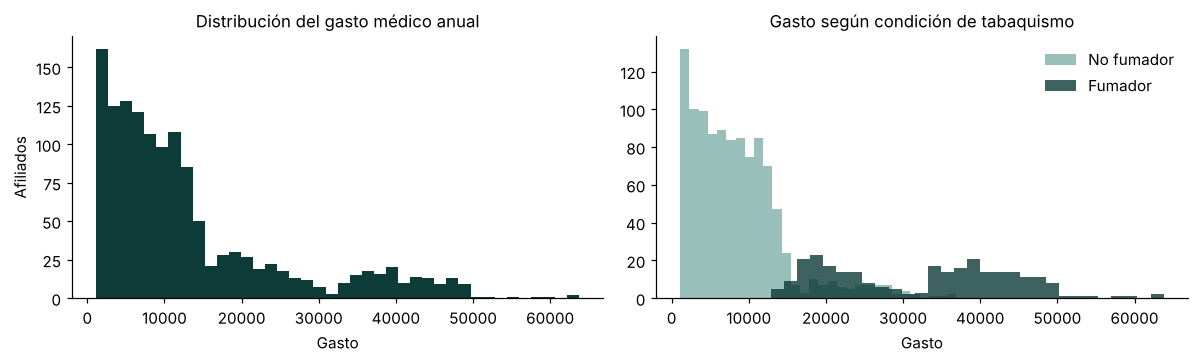

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), dpi=110)
a1.hist(d.charges, bins=40, color="#0C3B38")
a1.set_title("Distribución del gasto médico anual", fontsize=11)
a1.set_xlabel("Gasto"); a1.set_ylabel("Afiliados")
for et, col in [("no", "#7FB0A9"), ("yes", "#0C3B38")]:
    a2.hist(d[d.smoker == et].charges, bins=30, alpha=.8, color=col,
            label="Fumador" if et == "yes" else "No fumador")
a2.set_title("Gasto según condición de tabaquismo", fontsize=11)
a2.set_xlabel("Gasto"); a2.legend(frameon=False)
for a in (a1, a2):
    for s in ("top", "right"): a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 3. Preparación de variables

Aquí se aplica la decisión de gobernanza del hito **H2**: Compliance vetó el uso de `sex` por ser un
atributo protegido y de `region` por operar como aproximación socioeconómica. Ambas se excluyen
**antes** de entrenar, no después, de modo que no hay retrabajo.

Se incorporan dos términos de interacción entre tabaquismo e IMC. Esa decisión proviene del análisis
exploratorio y es la que más impacto tiene en el resultado.

In [7]:
d = d.copy()
d["fumador"]      = (d.smoker == "yes").astype(int)
d["imc30"]        = (d.bmi >= 30).astype(int)
d["fum_x_imc"]    = d.fumador * d.bmi
d["fum_x_imc30"]  = d.fumador * d.imc30

VARS_BASE  = ["age", "bmi", "children", "fumador"]
VARS_FINAL = VARS_BASE + ["fum_x_imc", "fum_x_imc30"]
VETADAS    = ["sex", "region"]

print("Variables disponibles en el conjunto :", list(d.columns[:7]))
print("Variables vetadas por Compliance (H2):", VETADAS)
print("Variables del modelo base            :", VARS_BASE)
print("Variables del modelo final           :", VARS_FINAL)
print()
print("RNF-01 · El conjunto no contiene identificadores directos y se excluyen los")
print("         atributos protegidos. Se cumple la condición de entrada del proyecto.")

Variables disponibles en el conjunto : ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']
Variables vetadas por Compliance (H2): ['sex', 'region']
Variables del modelo base            : ['age', 'bmi', 'children', 'fumador']
Variables del modelo final           : ['age', 'bmi', 'children', 'fumador', 'fum_x_imc', 'fum_x_imc30']

RNF-01 · El conjunto no contiene identificadores directos y se excluyen los
         atributos protegidos. Se cumple la condición de entrada del proyecto.


## 4. Partición de los datos

Estratificada por condición de tabaquismo, porque es la variable que más separa el gasto.

In [8]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te, d_tr, d_te = train_test_split(
    d[VARS_FINAL], d.charges.values, d,
    test_size=0.25, random_state=SEMILLA, stratify=d.fumador)

print(f"Entrenamiento: {len(X_tr)} registros")
print(f"Prueba       : {len(X_te)} registros")
print(f"Proporción de fumadores — entrenamiento: {d_tr.fumador.mean():.3f} | prueba: {d_te.fumador.mean():.3f}")

Entrenamiento: 1003 registros
Prueba       : 335 registros
Proporción de fumadores — entrenamiento: 0.204 | prueba: 0.206


## 5. Línea base: el método actual del cliente (OE-1)

Antes de proponer un modelo hay que medir cuánto se equivoca el método vigente. Sin esta referencia
no se puede demostrar que el proyecto aportó algo. El cliente estima hoy mediante el promedio de
gasto por tramo etario.

In [9]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def metricas(y_real, y_pred, nombre):
    return {
        "modelo": nombre,
        "R2":   round(r2_score(y_real, y_pred), 3),
        "MAE":  round(mean_absolute_error(y_real, y_pred), 0),
        "RMSE": round(float(np.sqrt(mean_squared_error(y_real, y_pred))), 0),
        "MAPE": round(float(np.mean(np.abs((y_real - y_pred) / y_real)) * 100), 1),
    }

TRAMOS  = [17, 25, 35, 45, 55, 65]
ETIQ    = ["18-25", "26-35", "36-45", "46-55", "56-64"]
d_tr = d_tr.copy(); d_te = d_te.copy()
d_tr["tramo"] = pd.cut(d_tr.age, bins=TRAMOS, labels=ETIQ)
d_te["tramo"] = pd.cut(d_te.age, bins=TRAMOS, labels=ETIQ)

promedio_tramo = d_tr.groupby("tramo", observed=True).charges.mean()
print("Promedio de gasto por tramo etario (calculado sobre entrenamiento):")
print(promedio_tramo.round(0).to_string())
print()

pred_base = d_te.tramo.map(promedio_tramo).astype(float).values
m_base = metricas(y_te, pred_base, "Promedio por tramo etario (línea base)")
print("LÍNEA BASE:", m_base)

Promedio de gasto por tramo etario (calculado sobre entrenamiento):
tramo
18-25     9503.0
26-35    10564.0
36-45    12920.0
46-55    16319.0
56-64    18227.0

LÍNEA BASE: {'modelo': 'Promedio por tramo etario (línea base)', 'R2': 0.102, 'MAE': 9141.0, 'RMSE': 11653.0, 'MAPE': 120.9}


## 6. Comparación de modelos

Se evalúan tres alternativas sobre el mismo conjunto de prueba. La comparación incluye un modelo
no lineal para verificar si la complejidad adicional se justifica.

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor

resultados = [m_base]

# M1 · Regresión lineal con las variables base
m1 = LinearRegression().fit(X_tr[VARS_BASE], y_tr)
resultados.append(metricas(y_te, m1.predict(X_te[VARS_BASE]), "Regresión lineal (variables base)"))

# M2 · Gradient boosting con las variables base
m2 = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                               min_samples_leaf=12, subsample=0.9,
                               random_state=SEMILLA).fit(X_tr[VARS_BASE], y_tr)
resultados.append(metricas(y_te, m2.predict(X_te[VARS_BASE]), "Gradient boosting"))

# M3 · Regresión lineal con interacción tabaquismo x IMC
m3 = LinearRegression().fit(X_tr[VARS_FINAL], y_tr)
pred_final = m3.predict(X_te[VARS_FINAL])
resultados.append(metricas(y_te, pred_final, "Regresión lineal con interacción"))

tabla = pd.DataFrame(resultados).set_index("modelo")
print(tabla.to_string())

                                           R2     MAE     RMSE   MAPE
modelo                                                               
Promedio por tramo etario (línea base)  0.102  9141.0  11653.0  120.9
Regresión lineal (variables base)       0.771  4008.0   5889.0   37.7
Gradient boosting                       0.857  2599.0   4658.0   31.6
Regresión lineal con interacción        0.868  2386.0   4463.0   27.2


In [11]:
mejor = tabla.R2.idxmax()
print("Modelo seleccionado:", mejor)
print()
print("Hallazgo relevante para RNF-02:")
print(f"  El modelo lineal con interacción (R2={tabla.loc['Regresión lineal con interacción','R2']}) supera")
print(f"  al gradient boosting (R2={tabla.loc['Gradient boosting','R2']}) en las cuatro métricas.")
print("  No hubo que elegir entre precisión y explicabilidad: una vez que la interacción")
print("  se hace explícita, el modelo más simple es además el más preciso.")
print()
mejora = (1 - tabla.loc[mejor, "MAE"] / tabla.loc[m_base["modelo"], "MAE"]) * 100
print(f"Mejora del MAE sobre la línea base: {mejora:.1f} %")

Modelo seleccionado: Regresión lineal con interacción

Hallazgo relevante para RNF-02:
  El modelo lineal con interacción (R2=0.868) supera
  al gradient boosting (R2=0.857) en las cuatro métricas.
  No hubo que elegir entre precisión y explicabilidad: una vez que la interacción
  se hace explícita, el modelo más simple es además el más preciso.

Mejora del MAE sobre la línea base: 73.9 %


## 7. Modelo final: coeficientes y estabilidad (RF-02)

Los coeficientes de un modelo lineal se leen directamente como el efecto de cada variable sobre el
gasto estimado. Esto es lo que permite cumplir RF-02 sin herramientas externas de interpretabilidad.

In [12]:
from sklearn.model_selection import cross_val_score, KFold

NOMBRES = {"age": "Edad (por año)", "bmi": "IMC (por punto)", "children": "N° de hijos",
           "fumador": "Tabaquismo (efecto base)", "fum_x_imc": "Tabaquismo × IMC (por punto)",
           "fum_x_imc30": "Tabaquismo × IMC ≥ 30 (salto)"}

coefs = pd.DataFrame({
    "término": [NOMBRES[v] for v in VARS_FINAL],
    "coeficiente": np.round(m3.coef_, 0),
}).set_index("término")
print("Intercepto:", round(float(m3.intercept_), 0))
print(coefs.to_string())
print()

cv = cross_val_score(LinearRegression(), d[VARS_FINAL], d.charges.values,
                     cv=KFold(5, shuffle=True, random_state=SEMILLA), scoring="r2")
print(f"Validación cruzada (5 particiones): R2 = {cv.mean():.3f} ± {cv.std():.3f}")
print("Los valores por partición:", np.round(cv, 3))
print("La baja dispersión confirma que el ajuste no depende de la partición elegida.")

Intercepto: -1413.0
                               coeficiente
término                                   
Edad (por año)                       263.0
IMC (por punto)                      -33.0
N° de hijos                          456.0
Tabaquismo (efecto base)            1304.0
Tabaquismo × IMC (por punto)         466.0
Tabaquismo × IMC ≥ 30 (salto)      15589.0

Validación cruzada (5 particiones): R2 = 0.861 ± 0.033
Los valores por partición: [0.879 0.856 0.908 0.807 0.853]
La baja dispersión confirma que el ajuste no depende de la partición elegida.


In [13]:
# Aporte de cada variable: caída del R2 al excluirla (incluidos sus términos de interacción)
BLOQUES = {
    "Tabaquismo":  ["fumador", "fum_x_imc", "fum_x_imc30"],
    "IMC":         ["bmi", "fum_x_imc", "fum_x_imc30"],
    "Edad":        ["age"],
    "N° de hijos": ["children"],
}
r2_completo = r2_score(y_te, pred_final)
aportes = []
for nombre, quitar in BLOQUES.items():
    conservar = [v for v in VARS_FINAL if v not in quitar]
    r2_sin = r2_score(y_te, LinearRegression().fit(X_tr[conservar], y_tr).predict(X_te[conservar]))
    aportes.append({"variable": nombre, "R2_sin_ella": round(r2_sin, 3),
                    "caída_del_R2": round(r2_completo - r2_sin, 3)})

ap = pd.DataFrame(aportes).sort_values("caída_del_R2", ascending=False).set_index("variable")
print("R2 del modelo completo:", round(r2_completo, 3))
print(ap.to_string())
print()
print("Nota metodológica: tabaquismo e IMC comparten los términos de interacción,")
print("de modo que sus aportes se solapan y no suman el total. Esa inseparabilidad")
print("es, precisamente, el hallazgo del proyecto.")

R2 del modelo completo: 0.868
             R2_sin_ella  caída_del_R2
variable                              
Tabaquismo         0.164         0.705
IMC                0.730         0.139
Edad               0.773         0.095
N° de hijos        0.864         0.004

Nota metodológica: tabaquismo e IMC comparten los términos de interacción,
de modo que sus aportes se solapan y no suman el total. Esa inseparabilidad
es, precisamente, el hallazgo del proyecto.


## 8. Intervalo de predicción al 90 % (RF-01)

El criterio de aceptación de RF-01 exige entregar un intervalo de confianza del 90 %, no solo un
valor puntual. Se estima mediante regresión cuantílica. **El primer ajuste no alcanzó la cobertura
comprometida y requirió recalibración**: queda registrado como desviación.

In [14]:
def intervalo(alpha_inf, alpha_sup, etiqueta):
    modelos = {}
    for a, k in [(alpha_inf, "inf"), (alpha_sup, "sup")]:
        modelos[k] = GradientBoostingRegressor(
            loss="quantile", alpha=a, n_estimators=400, max_depth=3,
            learning_rate=0.05, min_samples_leaf=12, random_state=SEMILLA
        ).fit(X_tr[VARS_FINAL], y_tr)
    lo = modelos["inf"].predict(X_te[VARS_FINAL])
    hi = modelos["sup"].predict(X_te[VARS_FINAL])
    cobertura = float(np.mean((y_te >= lo) & (y_te <= hi)) * 100)
    return {"ajuste": etiqueta, "cobertura_%": round(cobertura, 1),
            "amplitud_mediana": round(float(np.median(hi - lo)), 0),
            "cumple_90%": cobertura >= 88.0}, modelos

r_1, _      = intervalo(0.05, 0.95, "Cuantiles 5 % / 95 % (primer ajuste)")
r_2, qmods  = intervalo(0.02, 0.98, "Cuantiles 2 % / 98 % (recalibrado)")

print(pd.DataFrame([r_1, r_2]).set_index("ajuste").to_string())
print()
print("DESVIACIÓN D-1 registrada:")
print(f"  El primer ajuste cubrió {r_1['cobertura_%']} % frente al 90 % comprometido.")
print("  Causa: los cuantiles al 5/95 resultan estrechos para la cola alta del gasto.")
print(f"  Acción correctiva: recalibrar a 2/98. Cobertura resultante {r_2['cobertura_%']} %.")
print(f"  Costo asumido: el intervalo pasa de {r_1['amplitud_mediana']:.0f} a {r_2['amplitud_mediana']:.0f} de amplitud.")
print("  Estado de RF-01: CUMPLE tras la corrección.")

                                      cobertura_%  amplitud_mediana  cumple_90%
ajuste                                                                         
Cuantiles 5 % / 95 % (primer ajuste)         84.2           14548.0       False
Cuantiles 2 % / 98 % (recalibrado)           92.5           18090.0        True

DESVIACIÓN D-1 registrada:
  El primer ajuste cubrió 84.2 % frente al 90 % comprometido.
  Causa: los cuantiles al 5/95 resultan estrechos para la cola alta del gasto.
  Acción correctiva: recalibrar a 2/98. Cobertura resultante 92.5 %.
  Costo asumido: el intervalo pasa de 14548 a 18090 de amplitud.
  Estado de RF-01: CUMPLE tras la corrección.


## 9. Verificación de equidad (RNF-02)

El criterio original compara el error medio absoluto entre subgrupos y exige una diferencia inferior
al 10 %. Esa comparación resulta inadecuada cuando los grupos tienen niveles de gasto muy distintos,
de modo que se informan **ambas métricas** y se distingue entre atributos protegidos y variables del
modelo.

In [15]:
d_te = d_te.assign(pred=pred_final,
                   err_abs=np.abs(y_te - pred_final),
                   err_rel=np.abs(y_te - pred_final) / y_te)

DIMENSIONES = [
    ("Sexo",                    d_te.sex.map({"male": "hombre", "female": "mujer"}), "Atributo protegido, excluido del modelo"),
    ("Región",                  d_te.region,                                          "Proxy socioeconómico, excluido del modelo"),
    ("Tramo etario",            d_te.tramo.astype(str),                               "Variable del modelo"),
    ("Condición de tabaquismo", d_te.smoker.map({"yes": "fumador", "no": "no fumador"}), "Variable del modelo"),
]

filas = []
for nombre, serie, naturaleza in DIMENSIONES:
    g_abs = d_te.groupby(serie, observed=True).err_abs.mean()
    g_rel = d_te.groupby(serie, observed=True).err_rel.mean() * 100
    filas.append({
        "dimensión": nombre,
        "dispersión_error_absoluto_%": round(float((g_abs.max() - g_abs.min()) / g_abs.mean() * 100), 1),
        "dispersión_error_relativo_pp": round(float(g_rel.max() - g_rel.min()), 1),
        "naturaleza": naturaleza,
    })

eq = pd.DataFrame(filas).set_index("dimensión")
print(eq.to_string())
print()
protegidos = eq[eq.naturaleza.str.contains("excluido")]
print("Criterio comprometido: diferencia inferior al 10 %.")
print(f"  Sobre SEXO, el atributo con mayor riesgo de discriminación: "
      f"{eq.loc['Sexo','dispersión_error_relativo_pp']} pp — dentro del umbral, y sin usar esa variable.")
print(f"  Sobre REGIÓN: {eq.loc['Región','dispersión_error_relativo_pp']} pp — marginalmente por sobre.")
print()
print("DESVIACIÓN D-2 registrada: RNF-02 NO CUMPLE con el criterio tal como fue redactado.")
print("  Acción correctiva propuesta: reformular el criterio especificando")
print("  sobre qué atributos se evalúa y con qué métrica. Mientras tanto se reporta no cumplido.")

                         dispersión_error_absoluto_%  dispersión_error_relativo_pp                                 naturaleza
dimensión                                                                                                                    
Sexo                                            16.2                           8.5    Atributo protegido, excluido del modelo
Región                                          30.7                          12.4  Proxy socioeconómico, excluido del modelo
Tramo etario                                    40.3                          35.5                        Variable del modelo
Condición de tabaquismo                         48.0                          28.3                        Variable del modelo

Criterio comprometido: diferencia inferior al 10 %.
  Sobre SEXO, el atributo con mayor riesgo de discriminación: 8.5 pp — dentro del umbral, y sin usar esa variable.
  Sobre REGIÓN: 12.4 pp — marginalmente por sobre.

DESVIACIÓN D-2 registrad

In [16]:
# Detalle por subgrupo, para la ficha de modelo
print("=== ERROR RELATIVO MEDIO POR SUBGRUPO (%) ===")
for nombre, serie, _ in DIMENSIONES:
    g = (d_te.groupby(serie, observed=True).err_rel.mean() * 100).round(1)
    print(f"\n{nombre}:")
    print(g.to_string())

=== ERROR RELATIVO MEDIO POR SUBGRUPO (%) ===

Sexo:
sex
hombre    31.6
mujer     23.1

Región:
region
northeast    19.8
northwest    23.9
southeast    32.2
southwest    32.1

Tramo etario:
tramo
18-25    45.3
26-35    37.0
36-45    26.3
46-55    15.3
56-64     9.9

Condición de tabaquismo:
smoker
fumador        4.7
no fumador    33.0


## 10. Segmentación por gasto modificable (OE-4)

El objetivo del proyecto no termina en estimar: pide identificar dónde el gasto es **modificable**
mediante intervención preventiva, para focalizar los programas.

In [17]:
gasto_total = d.charges.sum()
SEGMENTOS = [
    ("Fumador · IMC ≥ 30",    (d.fumador == 1) & (d.imc30 == 1)),
    ("Fumador · IMC < 30",    (d.fumador == 1) & (d.imc30 == 0)),
    ("No fumador · IMC ≥ 30", (d.fumador == 0) & (d.imc30 == 1)),
    ("No fumador · IMC < 30", (d.fumador == 0) & (d.imc30 == 0)),
]
seg = pd.DataFrame([{
    "segmento": et,
    "afiliados": int(m.sum()),
    "%_cartera": round(m.mean() * 100, 1),
    "%_gasto": round(float(d[m].charges.sum() / gasto_total * 100), 1),
    "gasto_medio": round(float(d[m].charges.mean()), 0),
} for et, m in SEGMENTOS]).set_index("segmento")
seg["concentración"] = (seg["%_gasto"] / seg["%_cartera"]).round(1)
print(seg.to_string())
print()

pri = seg.loc["Fumador · IMC ≥ 30"]
ref = seg.loc["No fumador · IMC ≥ 30", "gasto_medio"]
print(f"Segmento prioritario: {pri['%_cartera']} % de la cartera, {pri['%_gasto']} % del gasto")
print(f"  Concentra {pri['concentración']} veces su peso en cartera.")
print(f"  Brecha frente a un no fumador con el mismo IMC: {pri['gasto_medio'] - ref:,.0f} por afiliado al año.")
print()
print("ADVERTENCIA METODOLÓGICA: esa brecha es el techo teórico de la intervención,")
print("no un ahorro comprometido. Mide una asociación observada entre grupos,")
print("no el efecto causal de dejar de fumar.")

                       afiliados  %_cartera  %_gasto  gasto_medio  concentración
segmento                                                                        
Fumador · IMC ≥ 30           145       10.8     33.9      41558.0            3.1
Fumador · IMC < 30           129        9.6     15.5      21363.0            1.6
No fumador · IMC ≥ 30        562       42.0     28.0       8843.0            0.7
No fumador · IMC < 30        502       37.5     22.6       7977.0            0.6

Segmento prioritario: 10.8 % de la cartera, 33.9 % del gasto
  Concentra 3.1 veces su peso en cartera.
  Brecha frente a un no fumador con el mismo IMC: 32,715 por afiliado al año.

ADVERTENCIA METODOLÓGICA: esa brecha es el techo teórico de la intervención,
no un ahorro comprometido. Mide una asociación observada entre grupos,
no el efecto causal de dejar de fumar.


In [18]:
# El hallazgo central, en cifras: el efecto del IMC es condicional al tabaquismo
tabla_int = d.groupby([d.fumador.map({1: "fumador", 0: "no fumador"}),
                       d.imc30.map({1: "IMC ≥ 30", 0: "IMC < 30"})]).charges.agg(["mean", "count"])
tabla_int.columns = ["gasto_medio", "afiliados"]
print(tabla_int.round(0).to_string())
print()
fu = tabla_int.loc[("fumador", "IMC ≥ 30"), "gasto_medio"] / tabla_int.loc[("fumador", "IMC < 30"), "gasto_medio"] - 1
nf = tabla_int.loc[("no fumador", "IMC ≥ 30"), "gasto_medio"] / tabla_int.loc[("no fumador", "IMC < 30"), "gasto_medio"] - 1
print(f"Alza al cruzar IMC 30 — fumadores   : {fu*100:+.0f} %")
print(f"Alza al cruzar IMC 30 — no fumadores: {nf*100:+.0f} %")

                     gasto_medio  afiliados
fumador    imc30                           
fumador    IMC < 30      21363.0        129
           IMC ≥ 30      41558.0        145
no fumador IMC < 30       7977.0        502
           IMC ≥ 30       8843.0        562

Alza al cruzar IMC 30 — fumadores   : +95 %
Alza al cruzar IMC 30 — no fumadores: +11 %


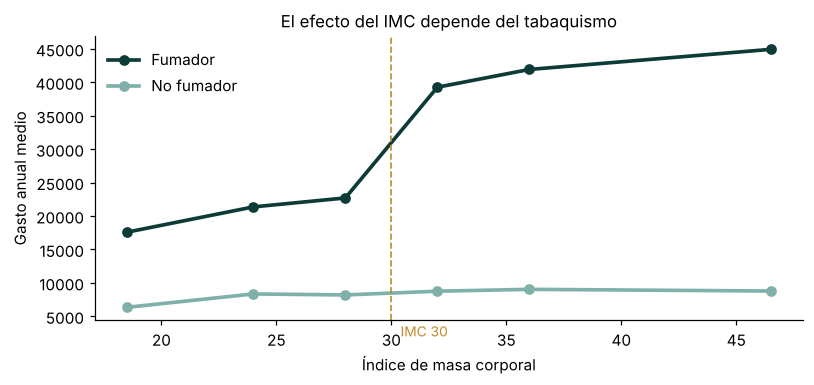

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 3.6), dpi=110)
for f, et, col in [(1, "Fumador", "#0C3B38"), (0, "No fumador", "#7FB0A9")]:
    xs, ys = [], []
    for lo, hi in [(15, 22), (22, 26), (26, 30), (30, 34), (34, 38), (38, 55)]:
        s = d[(d.bmi >= lo) & (d.bmi < hi) & (d.fumador == f)].charges
        if len(s) >= 5:
            xs.append((lo + hi) / 2); ys.append(s.mean())
    ax.plot(xs, ys, marker="o", lw=2.4, color=col, label=et)
ax.axvline(30, color="#C08A2E", lw=1.1, ls="--")
ax.text(30.4, 2000, "IMC 30", color="#C08A2E", fontsize=9)
ax.set_xlabel("Índice de masa corporal"); ax.set_ylabel("Gasto anual medio")
ax.set_title("El efecto del IMC depende del tabaquismo", fontsize=11)
ax.legend(frameon=False)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

## 11. Entregable funcional: pipeline serializado y función de estimación

El modelo se persiste junto con los modelos de cuantiles recalibrados, de modo que el entregable no
es un cuaderno sino un artefacto reutilizable. La función `estimar()` materializa **RF-01** (valor e
intervalo), **RF-02** (desglose del aporte de cada variable) y **RF-03** (simulación de escenarios
sobre factores modificables).

In [20]:
import joblib
from pathlib import Path

ARTEFACTO = {
    "modelo": m3,
    "cuantil_inferior": qmods["inf"],
    "cuantil_superior": qmods["sup"],
    "variables": VARS_FINAL,
    "intercepto": float(m3.intercept_),
    "coeficientes": {v: float(c) for v, c in zip(VARS_FINAL, m3.coef_)},
    "metricas": {"R2": float(r2_completo),
                 "MAE": float(mean_absolute_error(y_te, pred_final)),
                 "cobertura_intervalo_%": r_2["cobertura_%"]},
    "variables_vetadas": VETADAS,
    "semilla": SEMILLA,
    "version": "1.0",
}
joblib.dump(ARTEFACTO, "modelo_costo_medico_v1.joblib")
print("Artefacto guardado:", Path("modelo_costo_medico_v1.joblib").stat().st_size, "bytes")
print("Contenido:", list(ARTEFACTO.keys()))

Artefacto guardado: 814883 bytes
Contenido: ['modelo', 'cuantil_inferior', 'cuantil_superior', 'variables', 'intercepto', 'coeficientes', 'metricas', 'variables_vetadas', 'semilla', 'version']


In [21]:
def estimar(edad, imc, hijos, fumador, detalle=True):
    """Estima el costo médico anual de un afiliado.

    RF-01: devuelve el valor estimado y el intervalo al 90 %.
    RF-02: devuelve el aporte de cada variable al valor estimado.
    """
    fum = int(bool(fumador))
    fila = pd.DataFrame([{
        "age": edad, "bmi": imc, "children": hijos, "fumador": fum,
        "fum_x_imc": fum * imc, "fum_x_imc30": fum * int(imc >= 30),
    }])[VARS_FINAL]

    valor = float(m3.predict(fila)[0])
    inf   = float(qmods["inf"].predict(fila)[0])
    sup   = float(qmods["sup"].predict(fila)[0])

    salida = {"estimado": round(valor, 0),
              "intervalo_90": (round(inf, 0), round(sup, 0))}
    if detalle:
        salida["aporte_por_variable"] = {
            NOMBRES[v]: round(float(fila[v].iloc[0] * m3.coef_[i]), 0)
            for i, v in enumerate(VARS_FINAL) if fila[v].iloc[0] != 0
        }
        salida["base"] = round(float(m3.intercept_), 0)
    return salida


print("=== RF-01 y RF-02 · Estimación con intervalo y desglose ===")
caso = estimar(edad=45, imc=33.5, hijos=2, fumador=True)
for k, v in caso.items():
    print(f"  {k}: {v}")

=== RF-01 y RF-02 · Estimación con intervalo y desglose ===
  estimado: 42732.0
  intervalo_90: (30820.0, 52290.0)
  aporte_por_variable: {'Edad (por año)': 11824.0, 'IMC (por punto)': -1103.0, 'N° de hijos': 911.0, 'Tabaquismo (efecto base)': 1304.0, 'Tabaquismo × IMC (por punto)': 15619.0, 'Tabaquismo × IMC ≥ 30 (salto)': 15589.0}
  base: -1413.0


In [22]:
def simular(edad, imc, hijos, fumador, imc_objetivo=None, dejar_de_fumar=False):
    """RF-03: compara el escenario actual con uno de intervención preventiva."""
    actual = estimar(edad, imc, hijos, fumador, detalle=False)
    nuevo  = estimar(edad,
                     imc_objetivo if imc_objetivo is not None else imc,
                     hijos,
                     False if dejar_de_fumar else fumador,
                     detalle=False)
    dif = nuevo["estimado"] - actual["estimado"]
    return {
        "escenario_actual": actual["estimado"],
        "escenario_simulado": nuevo["estimado"],
        "diferencia": round(dif, 0),
        "variación_%": round(dif / actual["estimado"] * 100, 1),
    }


print("=== RF-03 · Simulación de escenarios ===")
print()
print("Afiliado de 45 años, IMC 33,5, dos hijos, fumador")
print()
print("a) Deja de fumar:")
for k, v in simular(45, 33.5, 2, True, dejar_de_fumar=True).items():
    print(f"     {k}: {v}")
print()
print("b) Reduce el IMC a 28 (bajo el umbral de obesidad), sigue fumando:")
for k, v in simular(45, 33.5, 2, True, imc_objetivo=28.0).items():
    print(f"     {k}: {v}")
print()
print("c) Ambas intervenciones:")
for k, v in simular(45, 33.5, 2, True, imc_objetivo=28.0, dejar_de_fumar=True).items():
    print(f"     {k}: {v}")
print()
print("OBSERVACIÓN: el escenario (c) no mejora al (a). Una vez que el afiliado deja")
print("de fumar, bajar el IMC deja de tener efecto favorable porque el coeficiente")
print("propio del IMC es levemente negativo. No es un defecto del modelo: es el")
print("hallazgo del proyecto expresado en una simulación. La prioridad de")
print("intervención es inequívoca: primero el tabaquismo.")

=== RF-03 · Simulación de escenarios ===

Afiliado de 45 años, IMC 33,5, dos hijos, fumador

a) Deja de fumar:


     escenario_actual: 42732.0
     escenario_simulado: 10219.0
     diferencia: -32513.0
     variación_%: -76.1

b) Reduce el IMC a 28 (bajo el umbral de obesidad), sigue fumando:
     escenario_actual: 42732.0
     escenario_simulado: 24759.0
     diferencia: -17973.0
     variación_%: -42.1

c) Ambas intervenciones:
     escenario_actual: 42732.0
     escenario_simulado: 10400.0
     diferencia: -32332.0
     variación_%: -75.7

OBSERVACIÓN: el escenario (c) no mejora al (a). Una vez que el afiliado deja
de fumar, bajar el IMC deja de tener efecto favorable porque el coeficiente
propio del IMC es levemente negativo. No es un defecto del modelo: es el
hallazgo del proyecto expresado en una simulación. La prioridad de
intervención es inequívoca: primero el tabaquismo.


## 12. Resumen de verificación de criterios de aceptación

Cierre del cuaderno: estado de cada requerimiento contra su criterio comprometido en el plan.

In [23]:
verificacion = pd.DataFrame([
    {"req": "RF-01",  "criterio": "Valor estimado más intervalo al 90 %",
     "resultado": f"Cobertura {r_2['cobertura_%']} % tras recalibrar", "estado": "CUMPLE"},
    {"req": "RF-01",  "criterio": "Error bajo el umbral acordado",
     "resultado": f"MAE {tabla.loc[mejor,'MAE']:,.0f} frente a {m_base['MAE']:,.0f} de la línea base", "estado": "CUMPLE"},
    {"req": "RF-02",  "criterio": "Aporte de variables global y por afiliado",
     "resultado": "Caída de R2 por variable y desglose en estimar()", "estado": "CUMPLE"},
    {"req": "RF-03",  "criterio": "Simulación sobre factores modificables",
     "resultado": "Función simular() operativa en el prototipo", "estado": "CUMPLE (prototipo)"},
    {"req": "RNF-01", "criterio": "Sin identificadores ni atributos protegidos",
     "resultado": "sex y region excluidas en H2", "estado": "CUMPLE"},
    {"req": "RNF-02", "criterio": "Diferencia de error entre subgrupos bajo 10 %",
     "resultado": f"{eq.loc['Sexo','dispersión_error_relativo_pp']} pp en sexo; "
                  f"{eq.loc['Tramo etario','dispersión_error_relativo_pp']} pp en tramo etario", "estado": "NO CUMPLE"},
    {"req": "RD-01",  "criterio": "Mínimo tres períodos anuales cerrados",
     "resultado": "Corte transversal único", "estado": "NO CUMPLE"},
    {"req": "RD-02",  "criterio": "Cobertura utilizable de IMC y tabaquismo",
     "resultado": f"{int(d[['bmi','smoker']].isna().sum().sum())} valores faltantes", "estado": "CUMPLE"},
]).set_index("req")

print(verificacion.to_string())
print()
print("Cumplidos:", int((verificacion.estado.str.startswith("CUMPLE")).sum()), "de", len(verificacion))

# Se exportan las métricas para alimentar el informe y la presentación
resumen = {
    "modelos": tabla.reset_index().to_dict("records"),
    "coeficientes": coefs.reset_index().to_dict("records"),
    "aportes": ap.reset_index().to_dict("records"),
    "intervalo": [r_1, r_2],
    "equidad": eq.reset_index().to_dict("records"),
    "segmentos": seg.reset_index().to_dict("records"),
    "verificacion": verificacion.reset_index().to_dict("records"),
    "cv": {"media": round(float(cv.mean()), 3), "sd": round(float(cv.std()), 3)},
}
with open("resumen_ep5.json", "w") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=1, default=float)
print("\nMétricas exportadas a resumen_ep5.json para el informe y la presentación.")

                                             criterio                                         resultado              estado
req                                                                                                                        
RF-01            Valor estimado más intervalo al 90 %                  Cobertura 92.5 % tras recalibrar              CUMPLE
RF-01                   Error bajo el umbral acordado         MAE 2,386 frente a 9,141 de la línea base              CUMPLE
RF-02       Aporte de variables global y por afiliado  Caída de R2 por variable y desglose en estimar()              CUMPLE
RF-03          Simulación sobre factores modificables       Función simular() operativa en el prototipo  CUMPLE (prototipo)
RNF-01    Sin identificadores ni atributos protegidos                      sex y region excluidas en H2              CUMPLE
RNF-02  Diferencia de error entre subgrupos bajo 10 %           8.5 pp en sexo; 35.5 pp en tramo etario           NO CUMPLE
RD-01   